In [1]:
# Cargar las librerias que se usarandurante el proyecto
import seaborn as sns 
import pandas as pd 
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix, mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
import numpy as np

In [2]:
# Cargar el dataset 
penguins = sns.load_dataset("penguins") 
print(penguins.head())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


In [3]:
# se ve cuantas columnas y filas hay
print('Hay ',penguins.shape[0],' filas.') #filas
print('Hay ',penguins.shape[1],' columnas.') # Columnas

Hay  344  filas.
Hay  7  columnas.


In [4]:
# Analizar el dataset para ver cuantas filas con algún elemento nulo hay
filas_con_nan = 0  # contador de filas con datos nulos
for index, row in penguins.iterrows():
  if row.isnull().any(): # verifica si hay un elemento nulo
    filas_con_nan += 1  # sube el contador

print(f'El número de filas con al menos un valor NaN es: {filas_con_nan}') 

El número de filas con al menos un valor NaN es: 11


In [5]:
# Existen filas con valores nulos, en concreto son 11. Se eliminan
penguinstest = penguins
penguinstest = penguinstest.dropna(axis=0)
penguinstest

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [6]:
# se repite el procedimiento con el df normal
penguins=penguins.dropna(axis=0)
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [7]:
# Se imprimen las especies estudiadas
especies=penguinstest['species'].unique()
print("Las especies son:", especies)
# Y el género 
genero=penguinstest['sex'].unique()
print("Los géneros son:", genero)

Las especies son: ['Adelie' 'Chinstrap' 'Gentoo']
Los géneros son: ['Male' 'Female']


In [8]:
# Se codifica la variable para hacerla numerica
# Primero se mapea
mapa_especies={
    'Adelie':1,
    'Chinstrap':2,
    'Gentoo':3
}
# ahora se cambia
penguinstest['species']=penguinstest['species'].replace(mapa_especies).infer_objects(copy=False)

# Se realiza el mismo procedimiento con el genero
mapa_genero={
    'Male':0,
    'Female':1
}
# y se cambia
penguinstest['sex']=penguinstest['sex'].replace(mapa_genero).infer_objects(copy=False)

C:\Users\ruben\AppData\Local\Temp\ipykernel_15052\2355951899.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  penguinstest['species']=penguinstest['species'].replace(mapa_especies).infer_objects(copy=False)
C:\Users\ruben\AppData\Local\Temp\ipykernel_15052\2355951899.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  penguinstest['sex']=penguinstest['sex'].replace(mapa_genero).infer_objects(copy=False)


In [9]:
# Se ve si cambió
especies2=penguinstest['species'].unique()
print("Especies codificadas: ", especies2)
genero2=penguinstest['sex'].unique()
print("Genero codificado: ", genero2)

Especies codificadas:  [1 2 3]
Genero codificado:  [0 1]


In [10]:
penguinstest.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,1,Torgersen,39.1,18.7,181.0,3750.0,0
1,1,Torgersen,39.5,17.4,186.0,3800.0,1
2,1,Torgersen,40.3,18.0,195.0,3250.0,1
4,1,Torgersen,36.7,19.3,193.0,3450.0,1
5,1,Torgersen,39.3,20.6,190.0,3650.0,0


In [11]:
# se normalizan las variables numericas
# inicializamos el minmaxscaler
scalminmax=MinMaxScaler()
# se identifican las variables numericas
numericaspenguinstest = penguinstest.select_dtypes(include=['float64', 'int64']).columns
print(numericaspenguinstest)

Index(['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'sex'],
      dtype='object')


In [12]:
# se normalizan las columnas de numericaspenguinstest excepto 'species' y 'sex'
penguinsminmaxtest=penguinstest
penguinsminmaxtest.loc[:,['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g']]=scalminmax.fit_transform(penguinsminmaxtest.loc[:,['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g']])

print("\nPenguins normalizado (primeras filas):")
print(penguinsminmaxtest.head())


Penguins normalizado (primeras filas):
   species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0        1  Torgersen        0.254545       0.666667           0.152542   
1        1  Torgersen        0.269091       0.511905           0.237288   
2        1  Torgersen        0.298182       0.583333           0.389831   
4        1  Torgersen        0.167273       0.738095           0.355932   
5        1  Torgersen        0.261818       0.892857           0.305085   

   body_mass_g  sex  
0     0.291667    0  
1     0.305556    1  
2     0.152778    1  
4     0.208333    1  
5     0.263889    0  


In [13]:
# Aplicamos los cambios al df original
penguins['species']=penguins['species'].replace(mapa_especies).infer_objects(copy=False)
penguins['sex']=penguins['sex'].replace(mapa_genero).infer_objects(copy=False)
penguinsminmax=penguins
penguinsminmax.loc[:,['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g']]=scalminmax.fit_transform(penguinsminmax.loc[:,['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g']])

print("\nPenguins normalizado (primeras filas):")
print(penguinsminmax.head())


Penguins normalizado (primeras filas):
   species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0        1  Torgersen        0.254545       0.666667           0.152542   
1        1  Torgersen        0.269091       0.511905           0.237288   
2        1  Torgersen        0.298182       0.583333           0.389831   
4        1  Torgersen        0.167273       0.738095           0.355932   
5        1  Torgersen        0.261818       0.892857           0.305085   

   body_mass_g  sex  
0     0.291667    0  
1     0.305556    1  
2     0.152778    1  
4     0.208333    1  
5     0.263889    0  


C:\Users\ruben\AppData\Local\Temp\ipykernel_15052\3651251291.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  penguins['species']=penguins['species'].replace(mapa_especies).infer_objects(copy=False)
C:\Users\ruben\AppData\Local\Temp\ipykernel_15052\3651251291.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  penguins['sex']=penguins['sex'].replace(mapa_genero).infer_objects(copy=False)


In [25]:
#  Se usan todas las columnas numericas para predecir especies
X = penguinsminmax[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g','sex']] # Características
y = penguinsminmax['species'] # Variable objetivo

# Se dividen los conjuntos en entrenamiento y prueba para entrenar los modelos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [26]:
# se comienza con la regresión logística 
logregmod = LogisticRegression(random_state=42, max_iter=1000) 

# se entrena el modelo
logregmod.fit(X_train, y_train)

# se obtienen las predicciones
ypredlogreg = logregmod.predict(X_test)

In [27]:
# se continua con el arbol de decision
treemod = DecisionTreeClassifier(random_state=42)

# Entrenar el modelo con los datos de entrenamiento
treemod.fit(X_train, y_train)

# se obtienen las predicciones
ypredtree = treemod.predict(X_test)

In [28]:
# Se calcula la precision (Accuracy) de ambos modelos en prueba
accuracy_logreg_test = accuracy_score(y_test, ypredlogreg)
accuracy_tree_test = accuracy_score(y_test, ypredtree)

print(f"Accuracy de Regresión Logística en Prueba: {accuracy_logreg_test:.4f}") # Formateamos a 4 decimales
print(f"Accuracy de Árbol de Decisión en Prueba: {accuracy_tree_test:.4f}")   # Formateamos a 4 decimales

Accuracy de Regresión Logística en Prueba: 0.9851
Accuracy de Árbol de Decisión en Prueba: 0.9552


In [29]:
# se calcula la precision (Precision) de ambos modelos en prueba
precision_logreg_test = precision_score(y_test, ypredlogreg, average='weighted')
precision_tree_test = precision_score(y_test, ypredtree, average='weighted')

print(f"Precisión de Regresión Logística en Prueba: {precision_logreg_test:.4f}") # redondear a 4 decimales
print(f"Precisión de Árbol de Decisión en Prueba: {precision_tree_test:.4f}")   # redondear a 4 decimales

Precisión de Regresión Logística en Prueba: 0.9857
Precisión de Árbol de Decisión en Prueba: 0.9552


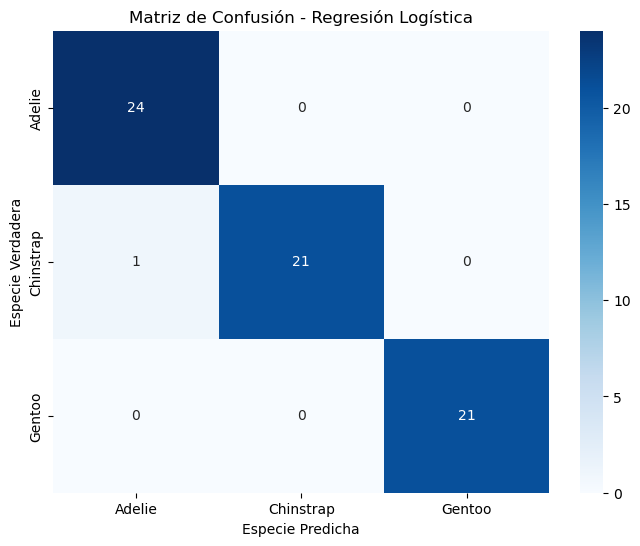

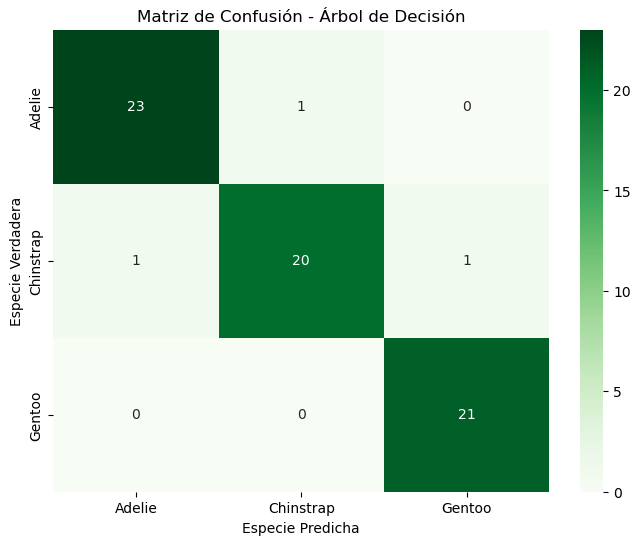

In [30]:
# se calcula la matriz de confusion de ambos modelos
cm_logreg = confusion_matrix(y_test, ypredlogreg)
cm_tree = confusion_matrix(y_test, ypredtree)

# etiquetas para las especies
etiquetas_especies = ['Adelie', 'Chinstrap', 'Gentoo'] # orden alfabético , el mismo que en los datos originales

# se crea la matriz de confusión para la Regresión Logística
plt.figure(figsize=(8, 6)) # tamaño
sns.heatmap(cm_logreg, annot=True, fmt="d", cmap="Blues", xticklabels=etiquetas_especies, yticklabels=etiquetas_especies) # mapa de calor
plt.title('Matriz de Confusión - Regresión Logística') # título
plt.xlabel('Especie Predicha') # Eje X
plt.ylabel('Especie Verdadera') # Eje Y
plt.show() # Mostrar la figura

# se crea la matríz de confusión para el árbol de decisiones
plt.figure(figsize=(8, 6)) #tamaño
sns.heatmap(cm_tree, annot=True, fmt="d", cmap="Greens", xticklabels=etiquetas_especies, yticklabels=etiquetas_especies) #mapa de calor
plt.title('Matriz de Confusión - Árbol de Decisión') #titulo
plt.xlabel('Especie Predicha') # Eje X
plt.ylabel('Especie Verdadera') # Eje Y
plt.show()

In [31]:
# se realiza la regresión 
# se usan las columnas excepto body_mass_g para prececir justamente body_mass_g
# dado que X e y ya se usaron anteriormente se usará Z y w

Z=penguinsminmax[['species','bill_length_mm', 'bill_depth_mm', 'flipper_length_mm','sex']] # caracteristicas
w = penguinsminmax[['body_mass_g']] # variable objetivo

In [32]:
# Se dividen los conjuntos en entrenamiento y prueba para entrenar los modelos
Z_train, Z_test, w_train, w_test = train_test_split(Z, w, test_size=0.2, random_state=42)

In [33]:
# se comienza con la regresión lineal
linregmod = LinearRegression()

# se entrena el modelo
linregmod.fit(Z_train,w_train)

# se obtienen las predicciones
wpredlinreg=linregmod.predict(Z_test)

In [34]:
# se continua con el Random Forest
ranforregmod = RandomForestRegressor(random_state=42)

# se entrena el modelo
ranforregmod.fit(Z_train, w_train)

# se obtienen las predicciones
wpredranforregmod=ranforregmod.predict(Z_test)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [35]:
# Se obtuvo un error, debido a que por algun motivo w_train parece tener dos dimensiones, se arregla esto
w_train_np = w_train.values  # Extraemos el array NumPy de w_train para volverlo algo unidimensional
w_train_raveled = w_train_np.ravel()

# se entrena el modelo
ranforregmod.fit(Z_train, w_train_raveled)

# se obtienen las predicciones
wpredranforregmod = ranforregmod.predict(Z_test)

In [36]:
# se procede a calular las metricas
# se calcula el  MSE para ambos modelos en el conjunto de PRUEBA de regresión
mse_linreg = mean_squared_error(w_test, wpredlinreg)
mse_ranfor = mean_squared_error(w_test, wpredranforregmod)
print('MSE de la regresión lineal: ', mse_linreg)
print('MSE del bosque aleatorio: ',mse_ranfor)

MSE de la regresión lineal:  0.007314694950521732
MSE del bosque aleatorio:  0.006212174875046065


In [37]:
# se calcula el MAE para ambos modelos en el conjunto de PRUEBA de regresión
mae_linreg = mean_absolute_error(w_test, wpredlinreg)
mae_ranfor = mean_absolute_error(w_test, wpredranforregmod)
print('MAE de la regresión lineal: ', mae_linreg)
print('MAE del bosque aleatorio: ',mae_ranfor)

MAE de la regresión lineal:  0.065981971086567
MAE del bosque aleatorio:  0.06447657545605305


In [38]:
# se calcula el R^2 Score para ambos modelos en el conjunto de PRUEBA de regresión
r2_linreg = r2_score(w_test, wpredlinreg)
r2_ranfor = r2_score(w_test, wpredranforregmod)
print('R2 Score de la regresión lineal: ', r2_linreg)
print('R2 Score del bosque aleatorio: ',r2_ranfor)

R2 Score de la regresión lineal:  0.8495123736347866
R2 Score del bosque aleatorio:  0.8721948819691219


In [39]:
# Se calcula el RMSE usando numpy.sqrt()
rmse_linreg = np.sqrt(mse_linreg)
rmse_ranfor = np.sqrt(mse_ranfor)
print('RMSE de la regresión lineal: ', rmse_linreg)
print('RMSE del bosque aleatorio: ',rmse_ranfor)

RMSE de la regresión lineal:  0.08552598991255074
RMSE del bosque aleatorio:  0.0788173513577186


In [40]:
# se procede a optimizar los hiperparametros
# Definición de hiperparámetros a evaluar
param_grid = {
    'max_depth': [None, 5, 10, 15],     # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],  # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4],   # Mínimo de muestras en un nodo hoja
    #'criterion': ['gini', 'entropy']   # Criterio de impureza
}


# Configuración y entrenamiento del modelo
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(), param_grid=param_grid, cv=5)
grid_search.fit(X_train, y_train) # son X y y dado que es treemod
# se inicializa GridSearchCV
grid_search_tremod = GridSearchCV(DecisionTreeClassifier(random_state=42), # Modelo base (Regresión Logística)
param_grid,       # Grilla de hiperparámetros
scoring='accuracy',      # Métrica para evaluar (accuracy para clasificación)
cv=5)      

In [41]:
# se ejecuta GridSearchCV
grid_search_tremod.fit(X_train, y_train) # son X y y dado que es Treemod

# se obtienen los resultados de GridSearchCV

print("Mejores hiperparámetros encontrados para Regresión Logística:")
print(grid_search_tremod.best_params_) # Muestra la mejor combinación de hiperparámetros

print("\nMejor Precision (Accuracy) en la Validación Cruzada para Regresión Logística:")
print(grid_search_tremod.best_score_) # Muestra los mejores puntajes en la validacion cruzada

Mejores hiperparámetros encontrados para Regresión Logística:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Mejor Precision (Accuracy) en la Validación Cruzada para Regresión Logística:
0.9547169811320755
